# EXP-001 test04 — Chọn nhóm AU đáng tin + cân bằng trọng số
Chỉ chạy lại **stage weight** trên vector/AU đã có của test03 (Drive) → **không cần GPU** (runtime CPU là đủ).
- `sel`: độ khớp chỉ tính trên các nhóm AU có Spearman LLM↔detector > `SPEARMAN_MIN` ở test03.
- `smile`: chuẩn hoá trọng số trung bình theo 5 mức xác suất cười của detector (không dùng nhãn).
- `class`: chuẩn hoá theo lớp CAER-S (dùng nhãn → chỉ để so sánh, không dùng để train).

# Cấu hình

In [1]:
SRC_RUN = "test03_vec500"     # thư mục đã có targets/, protos.npz, aus.csv
BRANCH = "exp/001-au-detector-filtering"
POOL, PROTO = "img", "templ"   # tổ hợp tốt nhất ở test03
SPEARMAN_MIN = 0.1
MAP = "linear"
W_MIN = 0.1

TRAIN_DATA = "/content/CAER-S_Face/train"
FACE_ZIP = "/content/drive/MyDrive/Datasets/CAERS_Face_train.zip"
EXP_DIR = f"/content/drive/MyDrive/ExpCLIP_output/exp001/{SRC_RUN}"   # output mới có tag riêng, không ghi đè test03
SCRIPT = "tools/precompute_au_weights.py"
PY = "python3"                # stage weight chỉ cần numpy → dùng Python sẵn của Colab

import os, subprocess
def run(cmd):
    """Chạy lệnh shell, in output trực tiếp; lỗi thì dừng cell (khác với `!`)."""
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         env={**os.environ, "PYTHONUNBUFFERED": "1"})
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"Lệnh lỗi (exit {p.returncode}) — xem output ở trên")

# Mount Drive, clone repo, giải nén ảnh (để xem ảnh mẫu)

In [3]:
from google.colab import drive
drive.mount('/content/drive')
assert os.path.exists(f"{EXP_DIR}/protos.npz") and os.path.exists(f"{EXP_DIR}/aus.csv"), "Chưa có kết quả test03"

Mounted at /content/drive


In [4]:
if not os.path.isdir("/content/Exp-CLIP"):
    !git clone -b $BRANCH https://github.com/huongng389/Exp-CLIP.git /content/Exp-CLIP
%cd /content/Exp-CLIP
!git checkout $BRANCH && git pull
!git log --oneline -1   # ghi lại commit vào research_log

Cloning into '/content/Exp-CLIP'...
remote: Enumerating objects: 367, done.
remote: Counting objects: 100% (367/367), done.
remote: Compressing objects: 100% (107/107), done.
remote: Total 367 (delta 272), reused 350 (delta 256), pack-reused 0 (from 0)
Receiving objects: 100% (367/367), 30.67 MiB | 19.40 MiB/s, done.
Resolving deltas: 100% (272/272), done.
/content/Exp-CLIP
Already on 'exp/001-au-detector-filtering'
Your branch is up to date with 'origin/exp/001-au-detector-filtering'.
Already up to date.
6020f56 (HEAD -> exp/001-au-detector-filtering, origin/exp/001-au-detector-filtering) EXP-001: select reliable AU groups and balance weights in weight stage


In [5]:
!mkdir -p /content/CAER-S_Face
!unzip -q -n "$FACE_ZIP" -d /content/CAER-S_Face
!ls /content/CAER-S_Face/train

Angry  Disgust	Fear  Happy  Neutral  Sad  Surprise


# Stage weight — chọn nhóm AU theo Spearman của test03

In [6]:
import pandas as pd
run(f'{PY} {SCRIPT} weight --out-dir {EXP_DIR} --pool {POOL} --proto {PROTO} --map {MAP} --w-min {W_MIN}')
sp = pd.read_csv(f"{EXP_DIR}/sanity_spearman_{POOL}-{PROTO}.csv")
GROUPS_SEL = sp[sp.spearman > SPEARMAN_MIN].group.tolist()
print("\nNhóm AU được giữ:", GROUPS_SEL)

[img-templ] 500 targets | 497 with AUs | 3 no face (w=1.0) | 0 not yet AU-detected (skipped)
agreement over 13 groups: mean 0.123 std 0.292 | weight mean 0.605 std 0.131 (map linear, balance none, w_min 0.1)
spearman per group: brow_raise -0.19, brow_lower +0.10, upper_lid_raise +0.15, cheek_raise +0.14, lid_tight -0.14, nose_wrinkle +0.06, lip_corner_pull +0.48, dimpler +0.14, lip_corner_depress -0.05, lip_stretch +0.21, lip_press +0.04, mouth_open +0.29, eyes_closed +0.32

Nhóm AU được giữ: ['upper_lid_raise', 'cheek_raise', 'lip_corner_pull', 'dimpler', 'lip_stretch', 'mouth_open', 'eyes_closed']


# Stage weight — 3 biến thể: sel / sel + smile / sel + class

In [7]:
TAGS = {}
for balance in ["none", "smile", "class"]:
    run(f'{PY} {SCRIPT} weight --out-dir {EXP_DIR} --pool {POOL} --proto {PROTO} --map {MAP} --w-min {W_MIN} '
        f'--groups {",".join(GROUPS_SEL)} --balance {balance}')
    TAGS[balance] = f"{POOL}-{PROTO}-sel" + ("" if balance == "none" else f"-{balance}")
    print()
TAGS["base (13 nhóm)"] = f"{POOL}-{PROTO}"

[img-templ-sel] 500 targets | 497 with AUs | 3 no face (w=1.0) | 0 not yet AU-detected (skipped)
agreement over 7 groups: mean 0.225 std 0.404 | weight mean 0.651 std 0.182 (map linear, balance none, w_min 0.1)
spearman per group: brow_raise -0.19, brow_lower +0.10, upper_lid_raise +0.15, cheek_raise +0.14, lid_tight -0.14, nose_wrinkle +0.06, lip_corner_pull +0.48, dimpler +0.14, lip_corner_depress -0.05, lip_stretch +0.21, lip_press +0.04, mouth_open +0.29, eyes_closed +0.32

[img-templ-sel-smile] 500 targets | 497 with AUs | 3 no face (w=1.0) | 0 not yet AU-detected (skipped)
agreement over 7 groups: mean 0.225 std 0.404 | weight mean 0.651 std 0.180 (map linear, balance smile, w_min 0.1)
spearman per group: brow_raise -0.19, brow_lower +0.10, upper_lid_raise +0.15, cheek_raise +0.14, lid_tight -0.14, nose_wrinkle +0.06, lip_corner_pull +0.48, dimpler +0.14, lip_corner_depress -0.05, lip_stretch +0.21, lip_press +0.04, mouth_open +0.29, eyes_closed +0.32

[img-templ-sel-class] 500 t

# Kiểm tra 1 — Trọng số trung bình theo lớp và theo mức cười\nKỳ vọng sau khi cân bằng: các lớp/mức cười gần bằng nhau.

In [8]:
import numpy as np
aus = pd.read_csv(f"{EXP_DIR}/aus.csv")
smile = aus.set_index("path")["AU12"]

dbg = {name: pd.read_csv(f"{EXP_DIR}/au_weights_debug_{tag}.csv") for name, tag in TAGS.items()}
by_class = pd.DataFrame({name: d.groupby("class")["weight"].mean() for name, d in dbg.items()})
by_class.loc["STD giữa lớp"] = by_class.std()
display(by_class.round(3))

d0 = dbg["base (13 nhóm)"]
q = pd.qcut(d0.path.map(smile), 5, labels=["cười Q1 (thấp)", "Q2", "Q3", "Q4", "Q5 (cao)"])
by_smile = pd.DataFrame({name: d.set_index("path").loc[d0.path, "weight"].groupby(q.values).mean() for name, d in dbg.items()})
display(by_smile.round(3))

,none,smile,class,base (13 nhóm)
class,,,,
Angry,0.648,0.654,0.651,0.590
Disgust,0.670,0.673,0.651,0.594
Fear,0.584,0.596,0.651,0.589
Happy,0.714,0.675,0.651,0.643
Neutral,0.674,0.682,0.651,0.631
Sad,0.622,0.627,0.651,0.585
Surprise,0.663,0.664,0.651,0.609
STD giữa lớp,0.042,0.031,0.000,0.023


/tmp/ipykernel_3694/2474217012.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  by_smile = pd.DataFrame({name: d.set_index("path").loc[d0.path, "weight"].groupby(q.values).mean() for name, d in dbg.items()})
/tmp/ipykernel_3694/2474217012.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  by_smile = pd.DataFrame({name: d.set_index("path").loc[d0.path, "weight"].groupby(q.values).mean() for name, d in dbg.items()})
/tmp/ipykernel_3694/2474217012.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain curren

,none,smile,class,base (13 nhóm)
cười Q1 (thấp),0.661,0.651,0.668,0.606
Q2,0.631,0.651,0.642,0.609
Q3,0.626,0.651,0.633,0.585
Q4,0.616,0.651,0.619,0.565
Q5 (cao),0.721,0.651,0.695,0.660


# Kiểm tra 2 — Phân bố & mức tương đồng giữa các biến thể

,none,smile,class,base (13 nhóm)
count,497.000,497.000,497.000,497.000
mean,0.651,0.651,0.651,0.605
std,0.182,0.180,0.179,0.131
min,0.149,0.154,0.156,0.229
25%,0.517,0.527,0.518,0.506
50%,0.674,0.673,0.670,0.611
75%,0.796,0.786,0.784,0.693
max,0.986,1.000,0.999,0.895


Spearman giữa các biến thể:


,none,smile,class,base (13 nhóm)
none,1.000,0.970,0.970,0.615
smile,0.970,1.000,0.962,0.568
class,0.970,0.962,1.000,0.598
base (13 nhóm),0.615,0.568,0.598,1.000


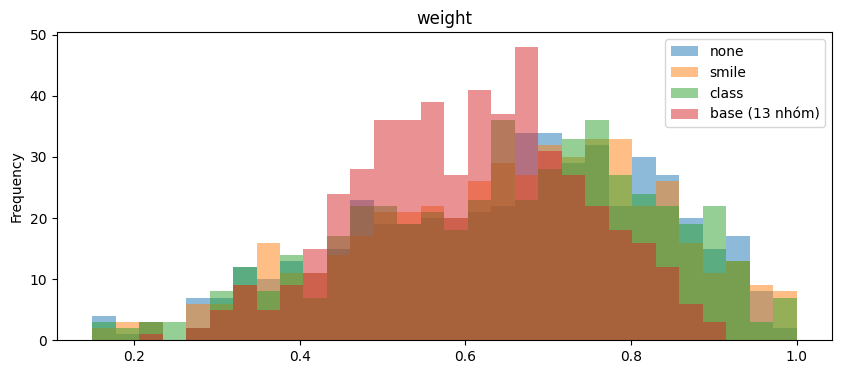

In [9]:
import matplotlib.pyplot as plt
W = pd.DataFrame({name: d.set_index("path")["weight"] for name, d in dbg.items()})
display(W.describe().round(3))
print("Spearman giữa các biến thể:")
display(W.corr(method="spearman").round(3))
W.plot.hist(bins=30, alpha=0.5, figsize=(10, 4)); plt.title("weight"); plt.show()

# Kiểm tra 3 — Ảnh trọng số thấp nhất / cao nhất (sel + smile)

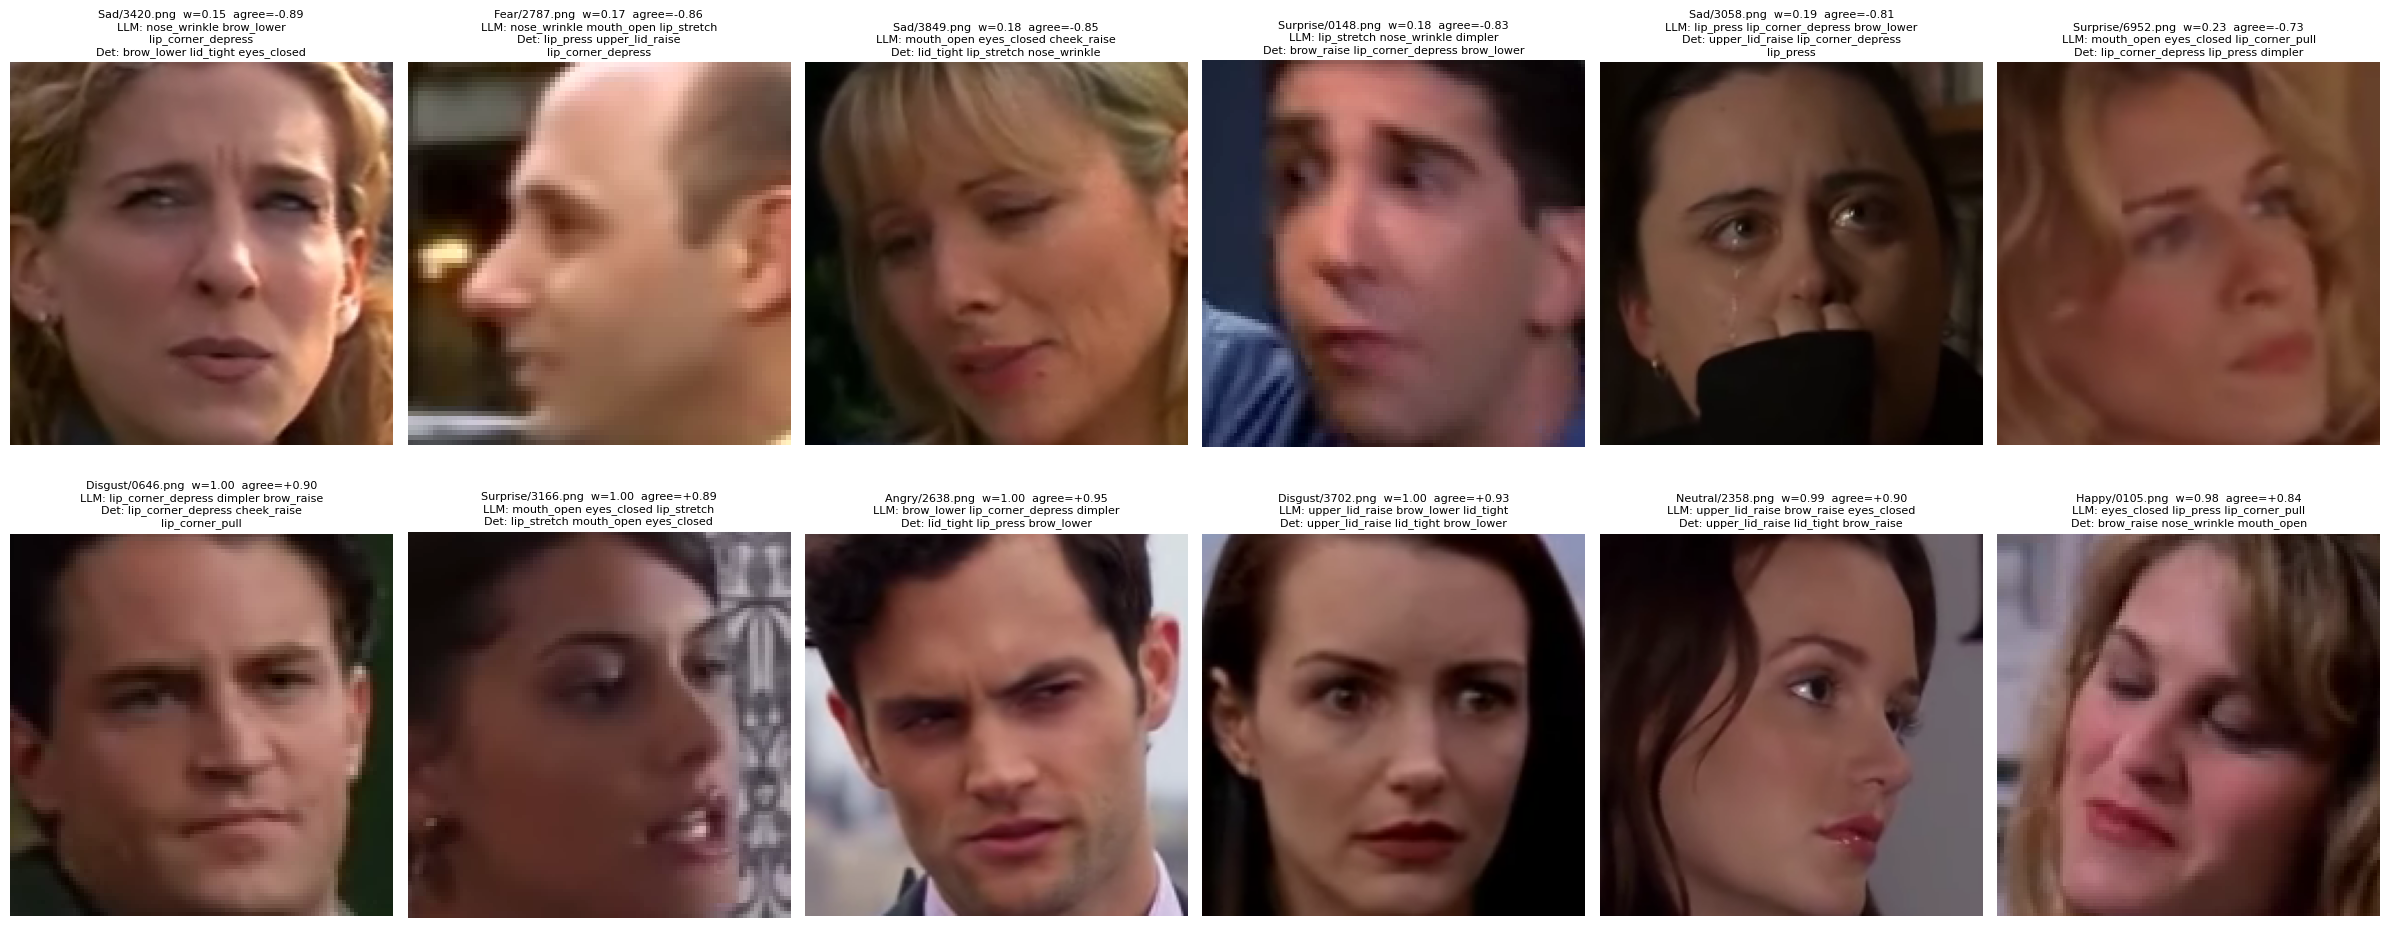

In [10]:
import textwrap
from PIL import Image
d = dbg["smile"]
show = pd.concat([d.nsmallest(6, "weight"), d.nlargest(6, "weight")])
fig, axes = plt.subplots(2, 6, figsize=(24, 10))
for ax, (_, r) in zip(axes.flat, show.iterrows()):
    ax.imshow(Image.open(f"{TRAIN_DATA}/{r.path}").convert("RGB"))
    ax.set_title(f"{r.path}  w={r.weight:.2f}  agree={r.agreement:+.2f}\n"
                 + "LLM: " + "\n".join(textwrap.wrap(r.llm_top3, 40)) + "\n"
                 + "Det: " + "\n".join(textwrap.wrap(r.detector_top3, 40)), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{EXP_DIR}/samples_{TAGS['smile']}.png", dpi=80)
plt.show()

# File kết quả mới trên Drive

In [11]:
!ls -lh "$EXP_DIR" | grep -- "-sel"

-rw------- 1 root root  54K Oct 13 14:42 au_weights_debug_img-templ-sel-class.csv
-rw------- 1 root root  54K Oct 13 14:42 au_weights_debug_img-templ-sel.csv
-rw------- 1 root root  54K Oct 13 14:42 au_weights_debug_img-templ-sel-smile.csv
-rw------- 1 root root  13K Oct 13 14:42 au_weights_img-templ-sel-class.json
-rw------- 1 root root  13K Oct 13 14:42 au_weights_img-templ-sel.json
-rw------- 1 root root  13K Oct 13 14:42 au_weights_img-templ-sel-smile.json
-rw------- 1 root root 887K Oct 13 14:42 samples_img-templ-sel-smile.png
-rw------- 1 root root 1.6K Oct 13 14:42 sanity_class_profile_img-templ-sel-class.csv
-rw------- 1 root root 1.6K Oct 13 14:42 sanity_class_profile_img-templ-sel.csv
-rw------- 1 root root 1.6K Oct 13 14:42 sanity_class_profile_img-templ-sel-smile.csv
-rw------- 1 root root  271 Oct 13 14:42 sanity_spearman_img-templ-sel-class.csv
-rw------- 1 root root  271 Oct 13 14:42 sanity_spearman_img-templ-sel.csv
-rw------- 1 root root  271 Oct 13 14:42 sanity_spearm